# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [2]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [3]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Wgraj plik szkolnictwo_wysze.csv:


Saving szkolnictwo_wysze.csv to szkolnictwo_wysze.csv


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [4]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

﻿name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [27]:
df = pd.read_csv(PLIK_LODZ, sep=";")
display(df.head())
print("Wymiary:", df.shape)
print(df.dtypes)

,name,rok,wartość,zmienna
0,Szkolnictwo wyższe,2012,22,uczelnie
1,Szkolnictwo wyższe,2013,22,uczelnie
2,Szkolnictwo wyższe,2014,23,uczelnie
3,Szkolnictwo wyższe,2015,21,uczelnie
4,Szkolnictwo wyższe,2016,20,uczelnie


Wymiary: (65, 4)
name       object
rok         int64
wartość     int64
zmienna    object
dtype: object


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* Separator to średnik. Kolumna wartość ma typ liczbowy, a polskie znaki wczytały się poprawnie.

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [29]:
print(df["zmienna"].value_counts())
szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")
szeroka

zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
rok,,,,,
2012,24825,55265,36281,91546,22
2013,22590,50007,33464,83471,22
2014,21343,48220,32456,80676,23
2015,19835,45584,30769,76353,21
2016,17662,44053,29908,73961,20
2017,19281,42990,29029,72019,22
2018,17046,39312,26253,65565,20
2019,15819,38146,26297,64443,19
2020,14082,39170,26155,65325,18


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [30]:
roznica = szeroka["kobiety"] + szeroka["mężczyźni"] - szeroka["ogółem"]
print(roznica)

rok
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    0
2024    0
dtype: int64


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [31]:
# Statystyki opisowe
display(szeroka.describe())

# Zmiana procentowa 2012–2024
zmiana_proc = (szeroka.loc[2024] - szeroka.loc[2012]) / szeroka.loc[2012] * 100
display(zmiana_proc.rename("Zmiana procentowa"))

# Nowe kolumny
szeroka["udzial_kobiet"] = szeroka["kobiety"] / szeroka["ogółem"]
szeroka["studenci_na_uczelnie"] = szeroka["ogółem"] / szeroka["uczelnie"]
display(szeroka)

zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
count,13.00,13.00,13.00,13.00,13.00
mean,17780.54,43010.92,28793.92,71804.85,19.54
std,3522.40,5391.05,3524.63,8900.65,2.44
min,14082.00,38146.00,25710.00,64272.00,15.00
25%,14756.00,39170.00,26049.00,65297.00,18.00
50%,17046.00,39958.00,26297.00,66002.00,20.00
75%,19835.00,45584.00,30769.00,76353.00,22.00
max,24825.00,55265.00,36281.00,91546.00,23.00


,Zmiana procentowa
zmienna,
absolwenci ogółem,-41.29
kobiety,-30.22
mężczyźni,-29.14
ogółem,-29.79
uczelnie,-31.82


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie,udzial_kobiet,studenci_na_uczelnie
rok,,,,,,,
2012,24825,55265,36281,91546,22,0.60,4161.18
2013,22590,50007,33464,83471,22,0.60,3794.14
2014,21343,48220,32456,80676,23,0.60,3507.65
2015,19835,45584,30769,76353,21,0.60,3635.86
2016,17662,44053,29908,73961,20,0.60,3698.05
2017,19281,42990,29029,72019,22,0.60,3273.59
2018,17046,39312,26253,65565,20,0.60,3278.25
2019,15819,38146,26297,64443,19,0.59,3391.74
2020,14082,39170,26155,65325,18,0.60,3629.17


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

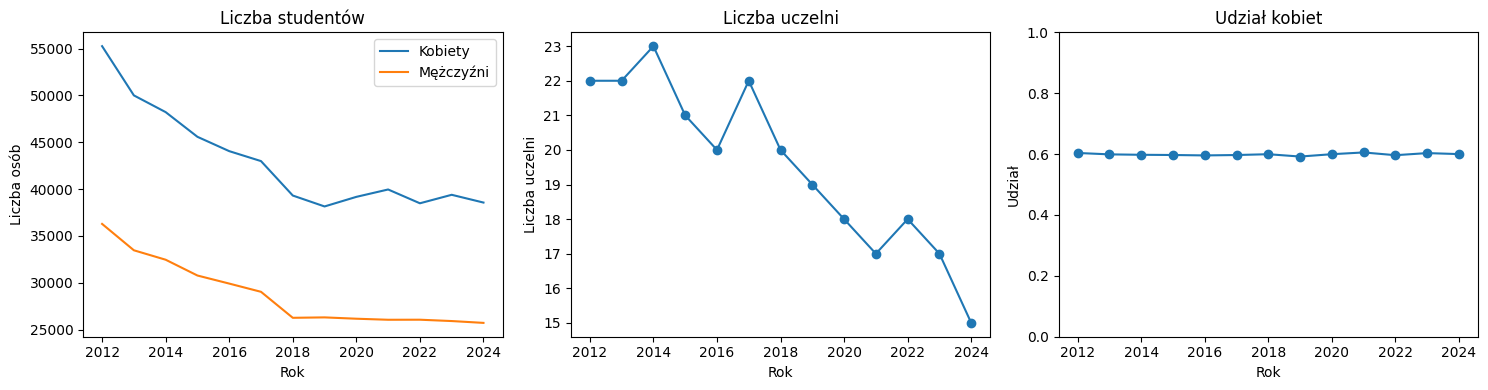

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# kobiety i mężczyźni
axes[0].plot(szeroka.index, szeroka["kobiety"], label="Kobiety")
axes[0].plot(szeroka.index, szeroka["mężczyźni"], label="Mężczyźni")
axes[0].set_title("Liczba studentów")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Liczba osób")
axes[0].legend()

# uczelnie
axes[1].plot(szeroka.index, szeroka["uczelnie"], marker="o")
axes[1].set_title("Liczba uczelni")
axes[1].set_xlabel("Rok")
axes[1].set_ylabel("Liczba uczelni")

# udział kobiet

axes[2].plot(szeroka.index, szeroka["udzial_kobiet"], marker="o")
axes[2].set_title("Udział kobiet")
axes[2].set_xlabel("Rok")
axes[2].set_ylabel("Udział")
axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* Można zaobserwować mocny spadek liczby uczelni. Przekłada się to również na liczbę studentów, która mocno spadła. Udział kobiet wśród studentów pozostał niemal stały przez cały okres czasu.

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** wykaz gminnej ewidencji zabytków · **link:** https://otwarte.miasto.lodz.pl/wp-content/uploads/2026/01/rejestr-zabytkow.csv · **data pobrania:** 28.10.2026

In [43]:
PLIK_ZABYTKI = "rejestr-zabytkow.csv"
upewnij_sie_ze_jest(PLIK_ZABYTKI)

df_moj = pd.read_csv(PLIK_ZABYTKI, sep=";", encoding="utf-8")
df_moj.columns = df_moj.columns.str.strip().str.replace("\n", " ")

print("\n--- Podgląd pierwszych wierszy ---")
display(df_moj.head())

print("\n--- Wymiary ramki danych (wiersze, kolumny) ---")
print(df_moj.shape)

print("\n--- Typy kolumn ---")
print(df_moj.dtypes)

print("\n--- Liczba braków danych (isna().sum()) ---")
print(df_moj.isna().sum())

Plik rejestr-zabytkow.csv jest na miejscu.

--- Podgląd pierwszych wierszy ---


,Lp,Ulica/ Aleja/ Plac,Numer porządkowy,Nazwa obiektu,Nr Rejestru Zabytków
0,1,Abramowskiego,1,Kamienica (budynek frontowy),NaN
1,2,Abramowskiego,3,Kamienica (budynek frontowy),NaN
2,3,Abramowskiego,7,Kamienica (budynek frontowy),NaN
3,4,Abramowskiego,14,Kamienica (budynek frontowy),NaN
4,5,Abramowskiego,16,Kamienica (budynek frontowy),NaN



--- Wymiary ramki danych (wiersze, kolumny) ---
(2769, 5)

--- Typy kolumn ---
Lp                       int64
Ulica/ Aleja/ Plac      object
Numer porządkowy        object
Nazwa obiektu           object
Nr Rejestru Zabytków    object
dtype: object

--- Liczba braków danych (isna().sum()) ---
Lp                         0
Ulica/ Aleja/ Plac         0
Numer porządkowy          13
Nazwa obiektu              0
Nr Rejestru Zabytków    2240
dtype: int64


=== STATYSTYKI ZBIORCZE ===
Łączna liczba zabytków w bazie: 2769
Liczba unikalnych ulic/obszarów: 339
Liczba unikalnych typów obiektów: 1502

--- Forma ochrony prawnej ---
                              Liczba  Udział (%)
Tylko GEZ (Gminna Ewidencja)    2240       80.90
Wpis do Rejestru Zabytków        529       19.10

--- Top 10 ulic z największą liczbą zabytków ---
Ulica/ Aleja/ Plac
Piotrkowska           233
AZP 67-51             187
Wólczańska             99
Gdańska                75
Kilińskiego            67
Tymienieckiego         64
Narutowicza            60
Kościuszki (aleja)     59
AZP 66-51              59
Sienkiewicza           57
Name: count, dtype: int64


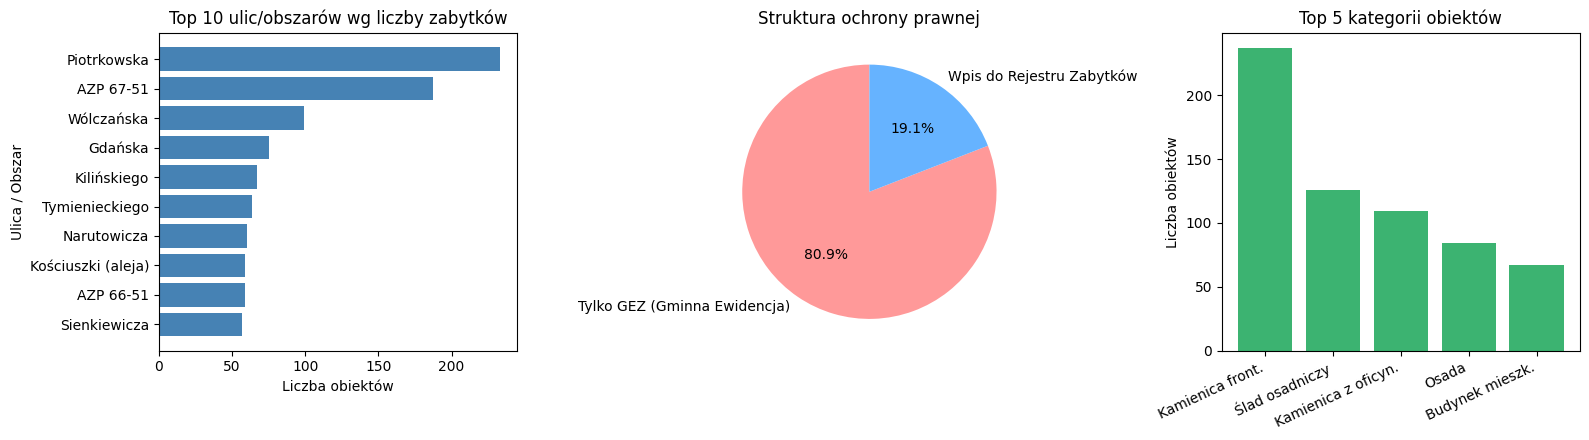

In [45]:
df_moj["Ulica/ Aleja/ Plac"] = df_moj["Ulica/ Aleja/ Plac"].str.strip()
df_moj["Nazwa obiektu"] = (
    df_moj["Nazwa obiektu"].str.replace("\n", " ").str.strip()
)

df_moj["wpis_do_rejestru"] = df_moj["Nr Rejestru Zabytków"].notna()

print("=== STATYSTYKI ZBIORCZE ===")
print(f"Łączna liczba zabytków w bazie: {len(df_moj)}")
print(
    f"Liczba unikalnych ulic/obszarów: {df_moj['Ulica/ Aleja/ Plac'].nunique()}"
)
print(f"Liczba unikalnych typów obiektów: {df_moj['Nazwa obiektu'].nunique()}")

status_ochrony = pd.DataFrame(
    {
        "Liczba": [
            (~df_moj["wpis_do_rejestru"]).sum(),
            df_moj["wpis_do_rejestru"].sum(),
        ],
        "Udział (%)": [
            (~df_moj["wpis_do_rejestru"]).mean() * 100,
            df_moj["wpis_do_rejestru"].mean() * 100,
        ],
    },
    index=["Tylko GEZ (Gminna Ewidencja)", "Wpis do Rejestru Zabytków"],
)
print("\n--- Forma ochrony prawnej ---")
print(status_ochrony.round(2))

print("\n--- Top 10 ulic z największą liczbą zabytków ---")
print(df_moj["Ulica/ Aleja/ Plac"].value_counts().head(10))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

top_ulice = df_moj["Ulica/ Aleja/ Plac"].value_counts().head(10)
axes[0].barh(top_ulice.index[::-1], top_ulice.values[::-1], color="steelblue")
axes[0].set_title("Top 10 ulic/obszarów wg liczby zabytków")
axes[0].set_xlabel("Liczba obiektów")
axes[0].set_ylabel("Ulica / Obszar")

ochrona_counts = status_ochrony["Liczba"]
axes[1].pie(
    ochrona_counts,
    labels=ochrona_counts.index,
    autopct="%1.1f%%",
    colors=["#ff9999", "#66b3ff"],
    startangle=90,
)
axes[1].set_title("Struktura ochrony prawnej")

top_obiekty = df_moj["Nazwa obiektu"].value_counts().head(5)
etykiety = [
    "Kamienica front.",
    "Ślad osadniczy",
    "Kamienica z oficyn.",
    "Osada",
    "Budynek mieszk.",
]
axes[2].bar(range(len(top_obiekty)), top_obiekty.values, color="mediumseagreen")
axes[2].set_xticks(range(len(top_obiekty)))
axes[2].set_xticklabels(etykiety, rotation=25, ha="right")
axes[2].set_title("Top 5 kategorii obiektów")
axes[2].set_ylabel("Liczba obiektów")

plt.tight_layout()
plt.show()

✍️ **Wnioski:** Większosć zabytków znajduje się w centrum Łodzi. Tylko 19% z zabutków w zbiorze jest wpisana do rejestru zabytków, większość jest tylko w ewidencji gminnej. Znaczną częścią zabytków są kamienice.

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [12]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

,age,bmi,avg_glucose_level
count,3000.00,3000.00,3000.00
mean,45.25,26.29,134.00
std,20.83,15.88,181.27
min,0.67,-5.20,-21.40
25%,28.00,21.28,85.59
50%,49.00,24.70,101.40
75%,63.00,28.88,127.43
max,80.00,105.60,1254.60


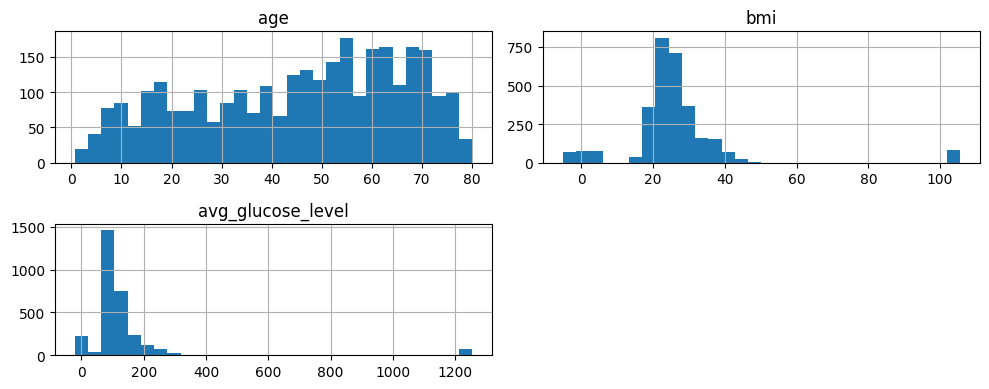

In [46]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]

# Statystyki opisowe
display(pacjenci[LICZBOWE].describe())

# Histogramy
pacjenci[LICZBOWE].hist(figsize=(10, 4), bins=30)
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:* Wiek od 0 do 120 lat, BMI od 10 do 60 oraz poziom glukozy od 20 do 800 mg/dl są możliwe.

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [47]:
# Maski wartości niemożliwych
zle_bmi = pacjenci["bmi"].notna() & ~pacjenci["bmi"].between(10, 60)
zla_glukoza = pacjenci["avg_glucose_level"].notna() & ~pacjenci["avg_glucose_level"].between(20, 800)
zly_wiek = pacjenci["age"].notna() & ~pacjenci["age"].between(0, 120)

# Liczebności
print("Nieprawidłowe BMI:", zle_bmi.sum())
print("Nieprawidłowa glukoza:", zla_glukoza.sum())
print("Nieprawidłowy wiek:", zly_wiek.sum())
niemozliwe = zle_bmi | zla_glukoza | zly_wiek
print("Pacjenci z co najmniej jedną niemożliwą wartością:", niemozliwe.sum())

# Zamiana wartości niemożliwych na NaN
pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan

Nieprawidłowe BMI: 300
Nieprawidłowa glukoza: 300
Nieprawidłowy wiek: 0
Pacjenci z co najmniej jedną niemożliwą wartością: 560


,age,bmi,avg_glucose_level
count,3000.00,2700.00,2700.00
mean,45.25,26.12,116.84
std,20.83,5.84,44.45
min,0.67,13.57,44.76
25%,28.00,21.94,89.47
50%,49.00,24.98,103.09
75%,63.00,28.85,127.84
max,80.00,47.62,332.91


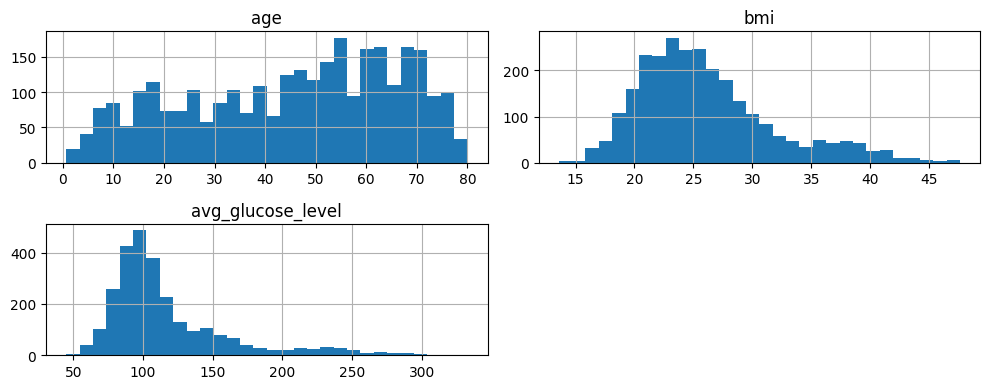

In [48]:
display(pacjenci[LICZBOWE].describe())
pacjenci[LICZBOWE].hist(figsize=(10, 4), bins=30)
plt.tight_layout()
plt.show()

## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

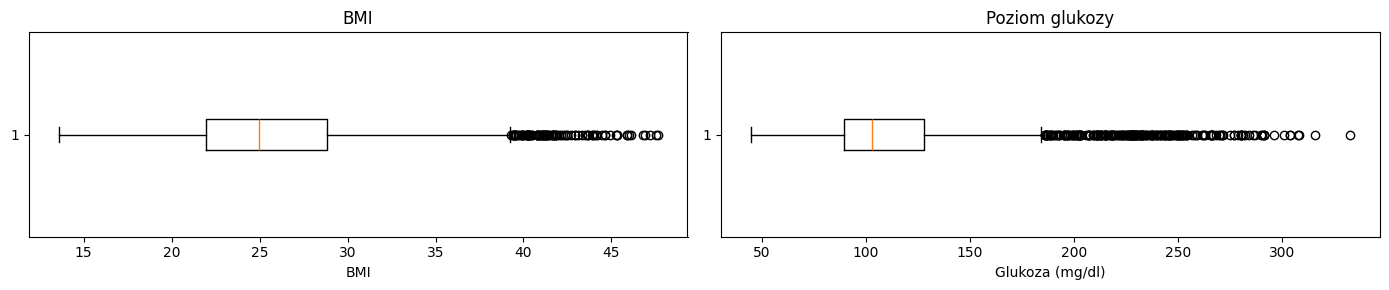

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))
axes[0].boxplot(pacjenci["bmi"].dropna(), orientation="horizontal")
axes[0].set_title("BMI")
axes[0].set_xlabel("BMI")
axes[1].boxplot(pacjenci["avg_glucose_level"].dropna(), orientation="horizontal")
axes[1].set_title("Poziom glukozy")
axes[1].set_xlabel("Glukoza (mg/dl)")
plt.tight_layout()
plt.show()

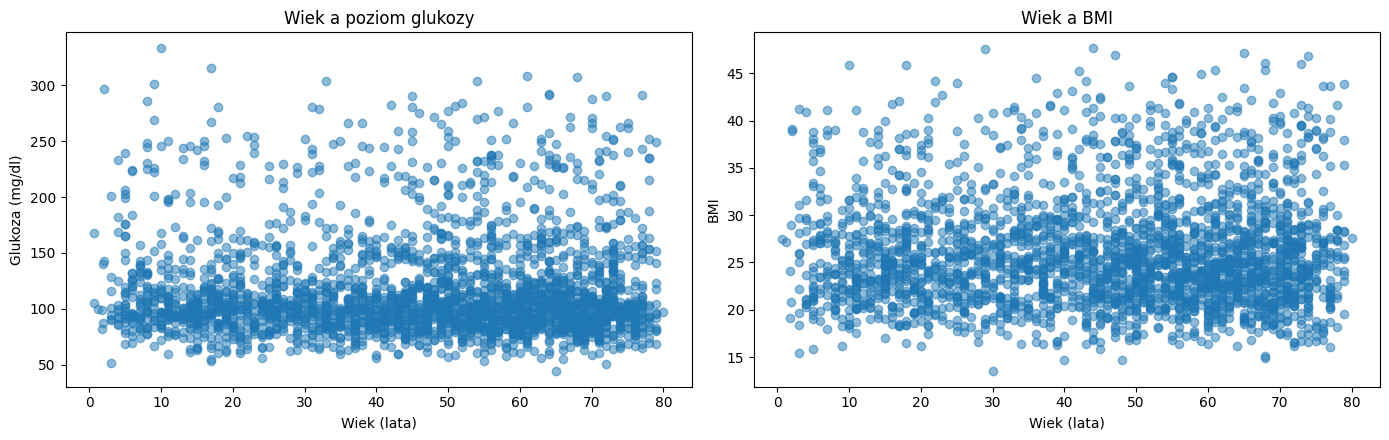

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(pacjenci["age"], pacjenci["avg_glucose_level"], alpha=0.5)
axes[0].set_title("Wiek a poziom glukozy")
axes[0].set_xlabel("Wiek (lata)")
axes[0].set_ylabel("Glukoza (mg/dl)")
axes[1].scatter(pacjenci["age"], pacjenci["bmi"], alpha=0.5)
axes[1].set_title("Wiek a BMI")
axes[1].set_xlabel("Wiek (lata)")
axes[1].set_ylabel("BMI")
plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:*  
1. Więcej punktów poza wąsami jest dla zmiennej avg_glucose_level. Leżą tylko po jednej stronie pudełka.
2. Wysokie wartości glukozy występują w każdym wieku. Przy przyjętych założeniach, zakładam że 10 latek z bardzo wysoką glukozą jest rzadkim przypadkiem

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [54]:
def maska_iqr(s, k=1.5):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    return ((s < q1 - k * iqr) | (s > q3 + k * iqr)).fillna(False)

def maska_z(s, prog=3):
    z = (s - s.mean()) / s.std()
    return (z.abs() > prog).fillna(False)

def maska_mad(s, prog=3.5):
    med = s.median()
    mad = (s - med).abs().median()
    if mad == 0 or pd.isna(mad):
        return pd.Series(False, index=s.index)
    wynik = (0.6745 * (s - med) / mad).abs() > prog
    return wynik.fillna(False)

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [55]:
wiersze = []
for kolumna in LICZBOWE:
    s = pacjenci[kolumna]
    wiersze.append({
        "zmienna": kolumna,
        "IQR 1,5": int(maska_iqr(s, 1.5).sum()),
        "IQR 3": int(maska_iqr(s, 3).sum()),
        "z-score": int(maska_z(s).sum()),
        "MAD": int(maska_mad(s).sum()),
        "skośność": s.skew()
    })
porownanie = pd.DataFrame(wiersze).set_index("zmienna")
porownanie

,"IQR 1,5",IQR 3,z-score,MAD,skośność
zmienna,,,,,
age,0,0,0,0,-0.33
bmi,100,0,23,33,0.99
avg_glucose_level,235,81,62,223,1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* Wiek pacjentów rozkłada się równomiernie, więc żadna metoda nic nie wykryła, natomiast jest wielu pacjentów z bardzo wysokim poziomem glukozy. Każda z metod liczy co innego więc wyniki są różne, przy dużym nierównomiernym rozłożeniu danych

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

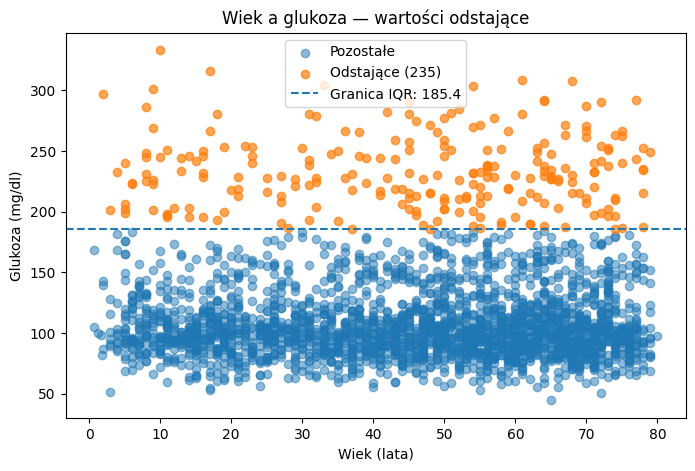

Liczba wartości powyżej granicy: 235


In [56]:
s = pacjenci["avg_glucose_level"]
odstajaca_glukoza = maska_iqr(s)
q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
granica = q3 + 1.5 * (q3 - q1)

plt.figure(figsize=(8, 5))
plt.scatter(pacjenci.loc[~odstajaca_glukoza, "age"],
            s.loc[~odstajaca_glukoza], alpha=0.5, label="Pozostałe")
plt.scatter(pacjenci.loc[odstajaca_glukoza, "age"],
            s.loc[odstajaca_glukoza], alpha=0.7,
            label=f"Odstające ({odstajaca_glukoza.sum()})")
plt.axhline(granica, linestyle="--", label=f"Granica IQR: {granica:.1f}")
plt.xlabel("Wiek (lata)")
plt.ylabel("Glukoza (mg/dl)")
plt.title("Wiek a glukoza — wartości odstające")
plt.legend()
plt.show()
print("Liczba wartości powyżej granicy:", (s > granica).sum())

### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

Odsetek udarów wśród pacjentów z odstającą glukozą: 21.70%
Odsetek udarów wśród pozostałych pacjentów: 21.92%


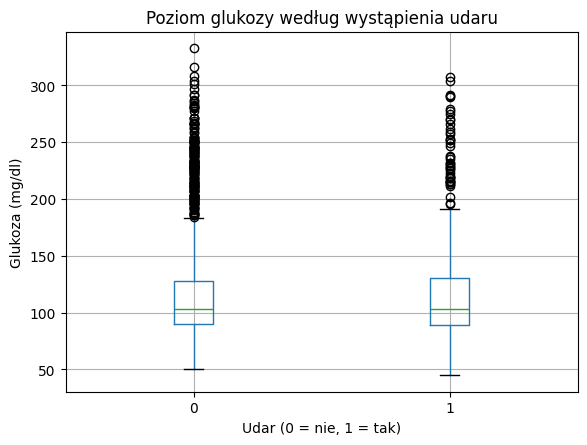

In [57]:
odstajaca_glukoza = maska_iqr(pacjenci["avg_glucose_level"])
odsetek_odstajace = pacjenci.loc[odstajaca_glukoza, "stroke"].mean() * 100
odsetek_pozostale = pacjenci.loc[~odstajaca_glukoza, "stroke"].mean() * 100
print(f"Odsetek udarów wśród pacjentów z odstającą glukozą: {odsetek_odstajace:.2f}%")
print(f"Odsetek udarów wśród pozostałych pacjentów: {odsetek_pozostale:.2f}%")

pacjenci.boxplot(column="avg_glucose_level", by="stroke")
plt.title("Poziom glukozy według wystąpienia udaru")
plt.suptitle("")
plt.xlabel("Udar (0 = nie, 1 = tak)")
plt.ylabel("Glukoza (mg/dl)")
plt.show()

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* Jeśli poziom glukozy jest związany z udarem, to wykreślenie danych osób z wysoką glukozą zakłamie wyniki przewidywania i nie będą one zgodne z realną statystyką

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [58]:
display(pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"]))

dziecko_pali = (
    (pacjenci["work_type"] == "children")
    & pacjenci["smoking_status"].isin(["smokes", "formerly smoked"])
)
maluch_student = (pacjenci["age"] <= 3) & (pacjenci["work_type"] == "student")

print("Dzieci palące lub palące w przeszłości:")
display(pacjenci.loc[dziecko_pali])
print("Dzieci do 3 lat ze statusem student:")
display(pacjenci.loc[maluch_student])

smoking_status,Unknown,formerly smoked,never smoked,smokes
work_type,,,,
Govt_job,16,63,94,67
Never_worked,1,30,36,35
Private,76,440,585,445
Self-employed,18,137,166,131
children,17,0,274,15
student,22,67,190,75


Dzieci palące lub palące w przeszłości:


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
111,A678646,Female,9.00,0,0,False,children,Rural,96.59,22.24,smokes,0
290,A844121,Male,13.00,0,0,False,children,Urban,163.31,20.14,smokes,0
336,A135365,Female,12.00,0,0,False,children,Urban,135.59,27.15,smokes,0
352,A810636,Male,14.00,0,0,False,children,Rural,203.26,NaN,smokes,0
361,A843508,Male,2.00,0,0,False,children,Urban,143.14,39.11,smokes,0
578,A161666,Male,3.00,0,0,False,children,Urban,NaN,15.47,smokes,0
600,A623587,Male,10.00,0,0,False,children,Urban,NaN,20.93,smokes,0
613,A892803,Male,13.00,0,0,False,children,Urban,132.17,25.04,smokes,0
741,A560170,Male,13.00,0,0,False,children,Urban,243.95,25.59,smokes,0
767,A390530,Male,13.00,0,0,False,children,Urban,91.28,28.47,smokes,0


Dzieci do 3 lat ze statusem student:


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
52,A582477,Female,1.80,0,0,False,student,Rural,82.20,24.05,formerly smoked,0


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* IQR i z-score oceniają pojedyncze zmienne, a nie sens kombinacji kategorii. Dlatego mogą nie wykryć, że osobno poprawne wartości tworzą nielogiczną kombinację.

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [59]:
from scipy.stats import chi2

X = pacjenci[LICZBOWE].dropna()
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)
prog = chi2.ppf(0.99, df=len(LICZBOWE))

print("Próg:", prog)
print("Liczba pacjentów odstających:", (d2 > prog).sum())
print("Cecha z największym udziałem w odległości:")
display((Z.loc[d2 > prog] ** 2).idxmax(axis=1).value_counts())

Próg: 11.344866730144373
Liczba pacjentów odstających: 73
Cecha z największym udziałem w odległości:


,count
avg_glucose_level,54
bmi,19


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

Odstający przed logarytmowaniem: 73
Odstający po logarytmowaniu: 31


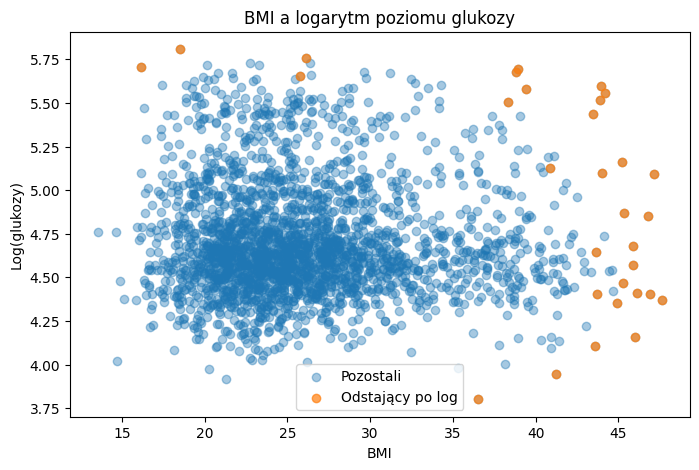

In [60]:
X_log = X.copy()
X_log["avg_glucose_level"] = np.log(X_log["avg_glucose_level"])
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)
prog_log = chi2.ppf(0.99, df=X_log.shape[1])
odlegli_log = d2_log > prog_log
print("Odstający przed logarytmowaniem:", int((d2 > prog).sum()))
print("Odstający po logarytmowaniu:", int(odlegli_log.sum()))

plt.figure(figsize=(8, 5))
plt.scatter(X_log["bmi"], X_log["avg_glucose_level"], alpha=0.4,
            label="Pozostali")
plt.scatter(X_log.loc[odlegli_log, "bmi"],
            X_log.loc[odlegli_log, "avg_glucose_level"],
            alpha=0.7, label="Odstający po log")
plt.xlabel("BMI")
plt.ylabel("Log(glukozy)")
plt.title("BMI a logarytm poziomu glukozy")
plt.legend()
plt.show()

✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* Nie, odległość Mahalanobisa przydaje się wtedy, gdy zmienne są ze sobą powiązane

### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [25]:
# TODO (dla chętnych)


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [62]:
# Flagi dla wszystkich pacjentów, z indeksem jak w oryginale
niemozliwa_wartosc = (
    (oryginal["bmi"].notna() & ~oryginal["bmi"].between(10, 60))
    | (oryginal["avg_glucose_level"].notna() & ~oryginal["avg_glucose_level"].between(20, 800))
    | (oryginal["age"].notna() & ~oryginal["age"].between(0, 120))
).fillna(False)

glukoza_iqr = maska_iqr(pacjenci["avg_glucose_level"])
nielogiczna_kategoria = dziecko_pali | maluch_student
odlegly_od_srodka = pd.Series(False, index=oryginal.index)
odlegly_od_srodka.loc[d2_log.index] = (d2_log > prog_log).values

flagi = pd.DataFrame({
    "niemozliwa_wartosc": niemozliwa_wartosc,
    "glukoza_iqr": glukoza_iqr,
    "nielogiczna_kategoria": nielogiczna_kategoria,
    "odlegly_od_srodka": odlegly_od_srodka
}, index=oryginal.index)

display(flagi)
print("\nLiczba pacjentów z każdą flagą:")
print(flagi.sum())
print("Liczba pacjentów z co najmniej jedną flagą:", flagi.any(axis=1).sum())

,niemozliwa_wartosc,glukoza_iqr,nielogiczna_kategoria,odlegly_od_srodka
0,False,False,False,False
1,False,False,False,False
2,False,False,False,False
3,False,False,False,False
4,False,False,False,False
...,...,...,...,...
2995,False,False,False,False
2996,False,False,False,False
2997,False,False,False,False
2998,False,False,False,False



Liczba pacjentów z każdą flagą:
niemozliwa_wartosc       560
glukoza_iqr              235
nielogiczna_kategoria     16
odlegly_od_srodka         31
dtype: int64
Liczba pacjentów z co najmniej jedną flagą: 806


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | usunąć | są błędami, więc nie są przydatne w analizie |
| wysoka glukoza (IQR) | zostawić | to prawdziwi pacjenci więc są kluczowi w analizie danych |
| nielogiczne kategorie | NaN | są pomyłkami w ankietach i wprowadzają szum |
| odlegli od środka | Flaga | nietypowe przypadki, ale to realni pacjenci  |